In [1]:
# 1. Manipulación de datos y visualización
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 2. Estadística y distancias (Parte II y Parte III)
from scipy import stats
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
# 3. Preprocesamiento, Clustering y Posicionamiento (scikit-learn >= 1.8)
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.manifold import MDS
# 4. Configuración de formato y gráficos
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
sns.set_theme(style="whitegrid")
print(f"Versión de scikit-learn: {sklearn.__version__}")

Versión de scikit-learn: 1.9.1


In [2]:
# Cargar las base de datos 
usuarios = pd.read_csv("fintual_users_dataset_2026.csv")
caracteristicas = pd.read_csv("user_demographics_2026.csv")
fintual_percepcion = pd.read_csv("fintual_perception_dataset_2026.csv")
# Resumen rápido de dimensiones y clientes únicos por tabla
base_datos = {
    "usuarios (comportamiento)": usuarios,
    "caracteristicas (demografía)": caracteristicas,
    "fintual_percepcion (encuesta)": fintual_percepcion
}
resumen_tablas = pd.DataFrame([
    {
        "Tabla": nombre,
        "Filas": df.shape[0],
        "Columnas": df.shape[1],
        "user_id únicos": df["user_id"].nunique(),
        "Filas duplicadas (exactas)": df.duplicated().sum()
    }
    for nombre, df in base_datos.items()
])
display(resumen_tablas)

,Tabla,Filas,Columnas,user_id únicos,Filas duplicadas (exactas)
0,usuarios (comportamiento),12025,6,12000,25
1,caracteristicas (demografía),12000,11,12000,0
2,fintual_percepcion (encuesta),21000,12,3000,0


## Parte 2.1: Auditoría de calidad de datos y análisis exploratorio 

In [3]:
# Estadisticas descriptivas y diagnostico en usuarios
variables_obj = [col for col in usuarios.columns if col != "user_id"]
desc_bruto = usuarios[variables_obj].describe().T
desc_bruto["nulos"] = usuarios[variables_obj].isna().sum()
desc_bruto["% nulos"] = (usuarios[variables_obj].isna().mean() * 100).round(2)
display(desc_bruto[["count", "nulos", "% nulos", "mean", "std", "min", "25%", "50%", "75%", "max"]])

,count,nulos,% nulos,mean,std,min,25%,50%,75%,max
age,"11,840.00",185,1.54,33.61,10.17,0.00,25.00,33.00,40.00,150.00
total_invested,"12,025.00",0,0.00,"8,106,127.96","13,929,064.99","15,500.00","302,300.00","2,824,300.00","9,637,000.00","239,386,000.00"
risk_tolerance,"11,647.00",378,3.14,3.22,1.21,0.00,2.00,3.00,4.00,5.00
months_active,"12,025.00",0,0.00,32.54,22.28,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"11,581.00",444,3.69,20.97,10.01,1.00,13.00,21.00,29.00,47.00


In [4]:
# Paso 1 de limpieza: Eliminar los 25 duplicados
total_duplicados  = usuarios.duplicated(subset="user_id").sum()
usuarios_copia = usuarios.drop_duplicates(subset="user_id").reset_index(drop=True)
print(f"Registros duplicados eliminados en 'usuarios': {total_duplicados} -> Quedan {len(usuarios_copia)} clientes únicos.")

Registros duplicados eliminados en 'usuarios': 25 -> Quedan 12000 clientes únicos.


In [5]:
# Paso 2 de auditoria: Encontrar valoores fuera de rango
edades_fuera_rango = usuarios_copia[usuarios_copia["age"].notna() & ~usuarios_copia["age"].between(18, 110)]
riesgo_fuera_rango = usuarios_copia[usuarios_copia["risk_tolerance"].notna() & ~usuarios_copia["risk_tolerance"].between(1, 5)]

print(f"\nEdades fuera de rango legal/biológico [18, 110]: {len(edades_fuera_rango)} casos")
print("Valores encontrados en 'age' fuera de rango:", sorted(edades_fuera_rango["age"].tolist()))
print(f"\nTolerancia al riesgo fuera de escala [1, 5]: {len(riesgo_fuera_rango)} casos (todos con valor = 0.0)")


Edades fuera de rango legal/biológico [18, 110]: 15 casos
Valores encontrados en 'age' fuera de rango: [0.0, 3.0, 7.0, 17.0, 17.0, 17.0, 17.0, 17.0, 17.0, 17.0, 17.0, 17.0, 112.0, 134.0, 150.0]

Tolerancia al riesgo fuera de escala [1, 5]: 70 casos (todos con valor = 0.0)


Patron en TOLERANCIA, los faltantes se concentran en clientes se concentran en clientes mas jovenes y nuevos

In [6]:
# 1. Clasificamos cada variable según su estado (Válido, Nulo o Fuera de rango) para comparar perfiles ()
estado_edad = np.where(usuarios_copia["age"].isna(), "Nulo (184)",
              np.where(~usuarios_copia["age"].between(18, 110), "Fuera de rango (15)", "Válido (11.801)"))
estado_riesgo = np.where(usuarios_copia["risk_tolerance"].isna(), "Nulo (377)",
                np.where(~usuarios_copia["risk_tolerance"].between(1, 5), "Fuera de rango (70)", "Válido (11.553)"))
estado_sesiones = np.where(usuarios_copia["app_sessions_month"].isna(), "Nulo (442)", "Válido (11.558)")
print("Patron en EDAD, los faltantes se concentran en clientes antiguos y de altos montos")
display(usuarios_copia.groupby(estado_edad)[["months_active", "total_invested", "app_sessions_month", "risk_tolerance"]].mean().round(2))
print("Patron en TOLERANCIA, los faltantes se concentran en clientes mas jovenes y nuevos")
display(usuarios_copia.groupby(estado_riesgo)[["age", "months_active", "total_invested", "app_sessions_month"]].mean().round(2))
print("Patrón en SESIONES APP, no se concentran en ningun tipo de cliente en especifico:")
display(usuarios_copia.groupby(estado_sesiones)[["age", "months_active", "total_invested", "risk_tolerance"]].mean().round(2))

Patron en EDAD, los faltantes se concentran en clientes antiguos y de altos montos


,months_active,total_invested,app_sessions_month,risk_tolerance
Fuera de rango (15),40.73,"12,974,206.67",19.86,3.53
Nulo (184),51.15,"17,586,988.04",21.80,3.32
Válido (11.801),32.26,"7,957,956.44",20.96,3.22


Patron en TOLERANCIA, los faltantes se concentran en clientes mas jovenes y nuevos


,age,months_active,total_invested,app_sessions_month
Fuera de rango (70),33.32,30.73,"7,579,897.14",20.78
Nulo (377),28.60,19.59,"4,507,414.85",24.28
Válido (11.553),33.77,32.99,"8,232,716.58",20.87


Patrón en SESIONES APP, no se concentran en ningun tipo de cliente en especifico:


,age,months_active,total_invested,risk_tolerance
Nulo (442),32.84,31.45,"7,661,805.43",3.27
Válido (11.558),33.64,32.60,"8,129,083.30",3.22


In [7]:
# A) Edad (184 nulos + 15 fuera de rango = 199 casos): Como los nulos se concentran en clientes con 51 meses de antigüedad, imputamos mediana condicional:
edad_valida = usuarios_copia["age"].between(18, 110)
mediana_edad_antiguos = usuarios_copia.loc[edad_valida & (usuarios_copia["months_active"] >= 50), "age"].median()
mediana_edad_general  = usuarios_copia.loc[edad_valida, "age"].median()                                           
imputar_edad = ~edad_valida
usuarios_copia.loc[imputar_edad, "age"] = np.where(
    usuarios_copia.loc[imputar_edad, "months_active"] >= 50,
    mediana_edad_antiguos,
    mediana_edad_general
)

# B) Tolerancia al riesgo (377 nulos + 70 en cero = 447 casos): Se imputa la mediana de la escala válida 1 a 5:
riesgo_valido = usuarios_copia["risk_tolerance"].between(1, 5)
mediana_riesgo = usuarios_copia.loc[riesgo_valido, "risk_tolerance"].median()
usuarios_copia.loc[~riesgo_valido, "risk_tolerance"] = mediana_riesgo

# C) Sesiones mensuales en la app (442 nulos): Al ser aleatorio (MCAR), se imputa con la mediana general (21.0 sesiones/mes)
mediana_sesiones = usuarios_copia["app_sessions_month"].median()  # 21.0
usuarios_copia["app_sessions_month"] = usuarios_copia["app_sessions_month"].fillna(mediana_sesiones)
print("\n Verificación post-limpieza de 'usuarios_copia' (0 nulos, rangos corregidos)")
display(usuarios_copia[variables_obj].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]])


 Verificación post-limpieza de 'usuarios_copia' (0 nulos, rangos corregidos)


,count,mean,std,min,25%,50%,75%,max
age,"12,000.00",33.70,9.98,18.00,25.00,33.00,41.00,67.00
total_invested,"12,000.00","8,111,871.90","13,938,875.54","15,500.00","302,925.00","2,825,000.00","9,642,425.00","239,386,000.00"
risk_tolerance,"12,000.00",3.23,1.17,1.00,2.00,3.00,4.00,5.00
months_active,"12,000.00",32.56,22.29,1.00,12.00,30.00,50.00,96.00
app_sessions_month,"12,000.00",20.98,9.82,1.00,13.00,21.00,29.00,47.00


In [8]:
# Estadísticas descriptivas y diagnóstico en caracteristicas
variables_caract = [col for col in caracteristicas.columns if col != "user_id"]
desc_caract = caracteristicas[variables_caract].describe(include="all").T
desc_caract["nulos"] = caracteristicas[variables_caract].isna().sum()
desc_caract["% nulos"] = (caracteristicas[variables_caract].isna().mean() * 100).round(2)
display(desc_caract[["count", "nulos", "% nulos", "unique", "top", "freq", "mean", "std", "min", "25%", "50%", "75%", "max"]])

,count,nulos,% nulos,unique,top,freq,mean,std,min,25%,50%,75%,max
region,11881,119,0.99,16,Metropolitana de Santiago,6830,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,11772,228,1.90,3,Masculino,6204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tramo_ingreso,11009,991,8.26,5,$1.200.001 - $2.500.000,3059,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ocupacion,12000,0,0.00,5,Dependiente,7707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
banco_principal,12000,0,0.00,12,Banco de Chile,2340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tiene_tarjeta_credito,12000,0,0.00,2,Sí,7989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
n_tarjetas_credito,"12,000.00",0,0.00,NaN,NaN,NaN,1.20,1.07,0.00,0.00,1.00,2.00,4.00
billetera_digital_principal,12000,0,0.00,5,Ninguna,4444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gasto_mensual_tarjetas_clp,"12,000.00",0,0.00,NaN,NaN,NaN,"1,155,643.58","1,046,950.30","48,000.00","440,000.00","848,000.00","1,519,000.00","14,602,000.00"
interes_fintual_card,"8,607.00",3393,28.28,NaN,NaN,NaN,3.58,1.08,1.00,3.00,4.00,4.00,5.00


#### Datos para imputar:
- Como genero tiene una opcion de "Otro/No declara" lo imputare con ella ya que es un MCAR, la gente se habra olvidado al responderla porque si se representa con otro genero o no queria declarlo estaba la opcion. 
- Para la region, primero quiero comprobar la region de los usuarios de fintual. Si los usuarios se concentran en un 90% en un region, imputare con ella porque de cada 100 clientes, solo 10 matematicamente hablando seran de otra region y en una base de datos de 12000 pasa piola. Como se comprobo en la tabla de abajo, la region top es santiago con un 56.92% por lo que prefiero imputar con "Sin dato" para no alterar los datos de una manera pobre. Podria aplicar otras tecnica como interpolacion, pero no vale la pena en nuestra opinion.
- Para tramo ingreso, es una variable sensible, o sea, MNAR. Fue un decision propia no querer contestarla, por lo que se prefiere imputar con no declara
- 'interes_fintual_card' (3.393 nulos, 28,28%) se mantiene tal cual para no alterar de manera artifical los datos de interes sobre la tarjeta y porque su dato en python es numerico.

In [9]:
# Conteo y porcentaje de clientes por región
tabla_regiones = pd.DataFrame({
    "Clientes": caracteristicas["region"].value_counts(dropna=False),
    "%": (caracteristicas["region"].value_counts(normalize=True, dropna=False) * 100).round(2)
})
display(tabla_regiones)

,Clientes,%
region,,
Metropolitana de Santiago,6830,56.92
Valparaíso,1208,10.07
Biobío,848,7.07
Antofagasta,422,3.52
Maule,422,3.52
O'Higgins,400,3.33
Araucanía,368,3.07
Coquimbo,328,2.73
Los Lagos,327,2.72


In [10]:
# Paso 3: Tratmiento de los nulos en caracteristicas
caracteristicas_copia = caracteristicas.copy()

# Cambiar los valores nulos segun lo que corresponda
caracteristicas_copia["genero"] = caracteristicas_copia["genero"].fillna("Otro / Prefiere no decir")  
caracteristicas_copia["region"] = caracteristicas_copia["region"].fillna("Sin dato")      
caracteristicas_copia["tramo_ingreso"] = caracteristicas_copia["tramo_ingreso"].fillna("No declara") 

# Verificamos si quienes no respondieron la encuesta in-app son distintos a quienes sí respondieron:
df_completo = usuarios_copia.merge(caracteristicas_copia, on="user_id", how="left")
df_completo["respondio_interes"] = np.where(df_completo["interes_fintual_card"].notna(), "Respondió", "No respondió")

print("Comparación entre quienes respondieron y NO respondieron 'interes_fintual_card'")
display(df_completo.groupby("respondio_interes")[["age", "months_active", "total_invested", "gasto_mensual_tarjetas_clp"]].mean().round(2))

Comparación entre quienes respondieron y NO respondieron 'interes_fintual_card'


,age,months_active,total_invested,gasto_mensual_tarjetas_clp
respondio_interes,,,,
No respondió,33.82,33.06,"8,118,454.26","1,162,691.42"
Respondió,33.65,32.36,"8,109,277.04","1,152,865.23"


Observando la tabla podemos detectar que los clientes que si respondieron no difieren de manera significativa con los que no respondieron

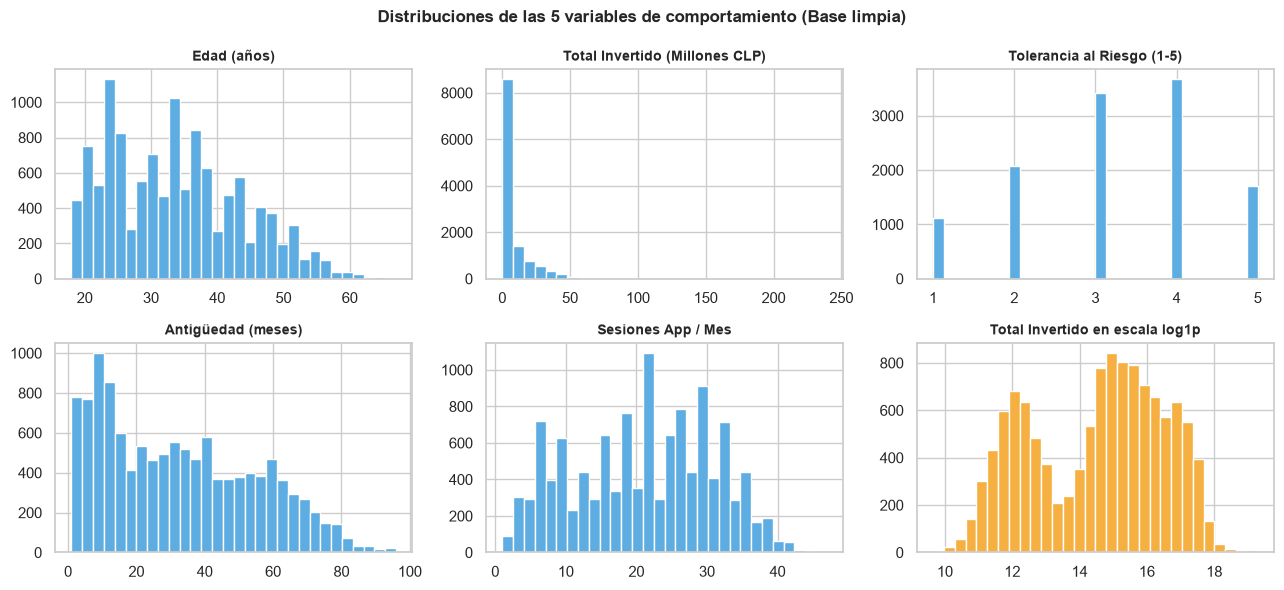

In [11]:
# 2. Histogramas de las 5 variables + comparación de 'total_invested' con log1p
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
nombres_esp = {
    "age": "Edad (años)",
    "total_invested": "Total Invertido (Millones CLP)",
    "risk_tolerance": "Tolerancia al Riesgo (1-5)",
    "months_active": "Antigüedad (meses)",
    "app_sessions_month": "Sesiones App / Mes"
}
for ax, col in zip(axes.flatten()[:5], variables_obj):
    serie = usuarios_copia[col] / 1_000_000 if col == "total_invested" else usuarios_copia[col]
    ax.hist(serie, bins=30, color="#5dade2", edgecolor="white")
    ax.set_title(nombres_esp[col], fontsize=10, fontweight="bold")
# Sexto panel: Total invertido transformado con log1p
axes[1, 2].hist(np.log1p(usuarios_copia["total_invested"]), bins=30, color="#f5b041", edgecolor="white")
axes[1, 2].set_title("Total Invertido en escala log1p", fontsize=10, fontweight="bold")
plt.suptitle("Distribuciones de las 5 variables de comportamiento (Base limpia)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

C:\Users\20fac\AppData\Local\Temp\ipykernel_21800\2002249290.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax1.boxplot(usuarios_copia["total_invested"] / 1_000_000, vert=False, widths=0.5, patch_artist=True,
C:\Users\20fac\AppData\Local\Temp\ipykernel_21800\2002249290.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax2.boxplot(np.log1p(usuarios_copia["total_invested"]), vert=False, widths=0.5, patch_artist=True,


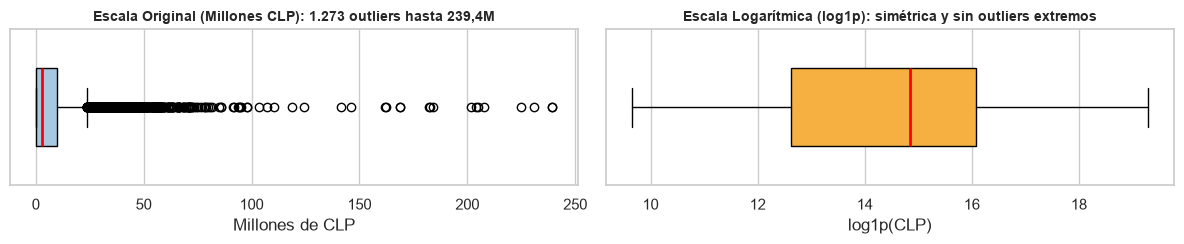

In [12]:
# 3. Boxplot comparativo: Total Invertido en CLP vs. Escala Logarítmica (log1p)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 2.6))
ax1.boxplot(usuarios_copia["total_invested"] / 1_000_000, vert=False, widths=0.5, patch_artist=True,
            boxprops=dict(facecolor="#a6c8e0"), medianprops=dict(color="red", linewidth=2))
ax1.set_title("Escala Original (Millones CLP): 1.273 outliers hasta 239,4M", fontsize=10, fontweight="bold")
ax1.set_xlabel("Millones de CLP")
ax1.set_yticks([])
ax2.boxplot(np.log1p(usuarios_copia["total_invested"]), vert=False, widths=0.5, patch_artist=True,
            boxprops=dict(facecolor="#f5b041"), medianprops=dict(color="red", linewidth=2))
ax2.set_title("Escala Logarítmica (log1p): simétrica y sin outliers extremos", fontsize=10, fontweight="bold")
ax2.set_xlabel("log1p(CLP)")
ax2.set_yticks([])
plt.tight_layout()
plt.show()

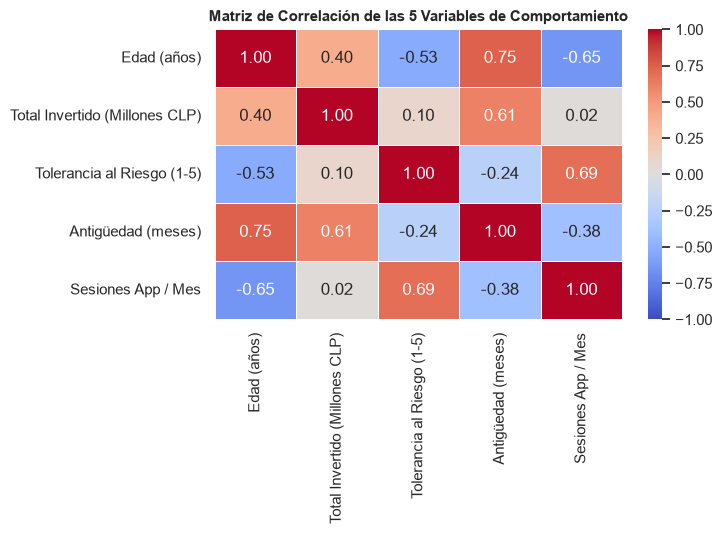

In [13]:
# MATRIZ DE CORRELACIÓN DE LAS 5 VARIABLES DE COMPORTAMIENTO
df_corr = usuarios_copia[variables_obj].rename(columns=nombres_esp)
matriz_corr = df_corr.corr()
plt.figure(figsize=(7.5, 5.5))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlación de las 5 Variables de Comportamiento", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

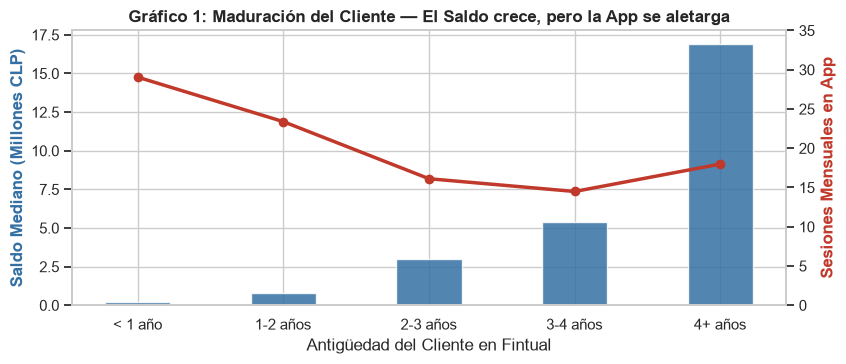

In [14]:
# GRÁFICO 1: Curva de maduración del cliente (Saldo mediano vs. Sesiones mensuales)
usuarios_copia["anios_activo"] = pd.cut(
    usuarios_copia["months_active"],
    bins=[0, 12, 24, 36, 48, 100],
    labels=["< 1 año", "1-2 años", "2-3 años", "3-4 años", "4+ años"]
)
maduracion = usuarios_copia.groupby("anios_activo", observed=False).agg(
    saldo_mediano=("total_invested", lambda x: x.median() / 1_000_000),
    sesiones_prom=("app_sessions_month", "mean")
).reset_index()
fig, ax1 = plt.subplots(figsize=(8.5, 3.8))
# Barras (Eje izquierdo): Saldo mediano en millones de CLP
ax1.bar(maduracion["anios_activo"], maduracion["saldo_mediano"], color="#3470a3", width=0.45, alpha=0.85)
ax1.set_xlabel("Antigüedad del Cliente en Fintual")
ax1.set_ylabel("Saldo Mediano (Millones CLP)", color="#3470a3", fontweight="bold")
# Línea (Eje derecho twinx): Sesiones mensuales promedio
ax2 = ax1.twinx()
ax2.plot(maduracion["anios_activo"], maduracion["sesiones_prom"], color="#c0392b", marker="o", linewidth=2.5)
ax2.set_ylabel("Sesiones Mensuales en App", color="#c0392b", fontweight="bold")
ax2.set_ylim(0, 35)
ax2.grid(False)
plt.title("Gráfico 1: Maduración del Cliente — El Saldo crece, pero la App se aletarga", fontweight="bold")
plt.tight_layout()
plt.show()

Grafico 1: A medida que aumenta la antigüedad del cliente, el saldo mediano crece de forma sostenida (de 0,19 M en el primer año a 16,9 M con más de 4 años), mientras que la frecuencia de uso de la app cae de 29,1 sesiones mensuales en el primer año a 14,5 en el tramo de 3 a 4 años y repunta levemente a 18,0 en el de 4+ años. Es decir, la caída no es estrictamente progresiva. Este comportamiento admite dos hipótesis:
- Mayor confianza en el producto y maduración: El usuario entiende la idea de inversión a largo plazo y confía en la gestión.
- Pérdida de interés por la aplicación: El usuario solamente ingresa cuando quiere hacer algún tipo de transacción.
Ninguna de las dos se puede probar con estos datos; sirven como hipótesis a validar en las entrevistas.

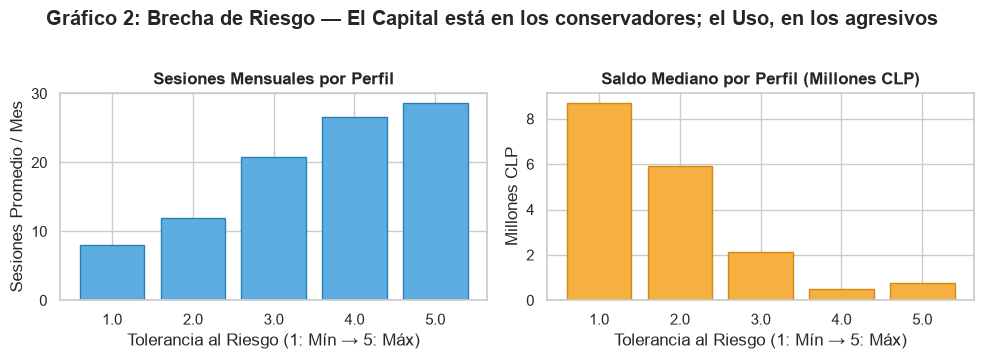

In [15]:
# GRÁFICO 2: Engagement y Saldo por Nivel de Tolerancia al Riesgo
riesgo = usuarios_copia.groupby("risk_tolerance").agg(
    sesiones_prom=("app_sessions_month", "mean"),
    saldo_mediano=("total_invested", lambda x: x.median() / 1_000_000)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

# Panel izquierdo: Sesiones mensuales
ax[0].bar(riesgo["risk_tolerance"].astype(str), riesgo["sesiones_prom"], color="#5dade2", edgecolor="#2980b9")
ax[0].set_title("Sesiones Mensuales por Perfil", fontweight="bold")
ax[0].set_xlabel("Tolerancia al Riesgo (1: Mín → 5: Máx)")
ax[0].set_ylabel("Sesiones Promedio / Mes")

# Panel derecho: Saldo mediano
ax[1].bar(riesgo["risk_tolerance"].astype(str), riesgo["saldo_mediano"], color="#f5b041", edgecolor="#d68910")
ax[1].set_title("Saldo Mediano por Perfil (Millones CLP)", fontweight="bold")
ax[1].set_xlabel("Tolerancia al Riesgo (1: Mín → 5: Máx)")
ax[1].set_ylabel("Millones CLP")

plt.suptitle("Gráfico 2: Brecha de Riesgo — El Capital está en los conservadores; el Uso, en los agresivos", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Grafico 2: Este grafico evidencia una relación inversa entre patrimonio y frecuencia de uso: mientras los usuarios conservadores concentran el grueso del capital en Fintual con una interacción esporádica, los clientes con perfiles arriesgados son los más activos digitalmente en la app, a pesar de mantener saldos considerablemente menores.

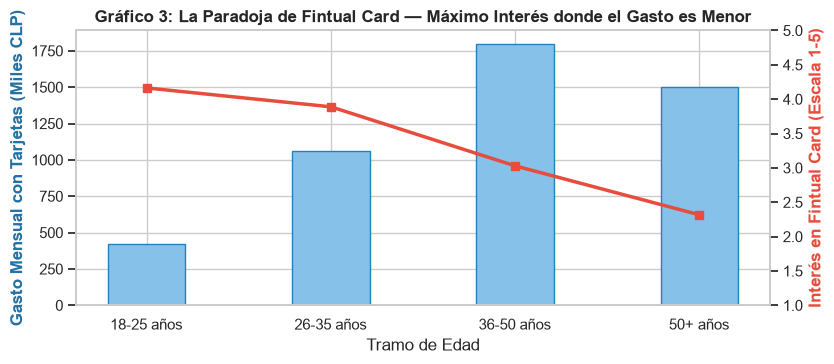

In [16]:
# GRÁFICO 3: Paradoja de Fintual Card (Gasto mensual con tarjetas vs. Interés declarado)
df_completo = usuarios_copia.merge(caracteristicas_copia, on="user_id", how="left")

df_completo["tramo_edad"] = pd.cut(
    df_completo["age"],
    bins=[17, 25, 35, 50, 100],
    labels=["18-25 años", "26-35 años", "36-50 años", "50+ años"]
)

paradoja = df_completo.groupby("tramo_edad", observed=False).agg(
    gasto_k=("gasto_mensual_tarjetas_clp", lambda x: x.mean() / 1_000),
    interes_prom=("interes_fintual_card", "mean")
).reset_index()

fig, ax1 = plt.subplots(figsize=(8.5, 3.8))

# Barras (Eje izquierdo): Gasto mensual con tarjetas en miles de CLP
ax1.bar(paradoja["tramo_edad"], paradoja["gasto_k"], color="#85c1e9", edgecolor="#2980b9", width=0.42)
ax1.set_xlabel("Tramo de Edad")
ax1.set_ylabel("Gasto Mensual con Tarjetas (Miles CLP)", color="#2471a3", fontweight="bold")

# Línea (Eje derecho twinx): Interés promedio en Fintual Card (1 a 5)
ax2 = ax1.twinx()
ax2.plot(paradoja["tramo_edad"], paradoja["interes_prom"], color="#e74c3c", marker="s", linewidth=2.5)
ax2.set_ylabel("Interés en Fintual Card (Escala 1-5)", color="#e74c3c", fontweight="bold")
ax2.set_ylim(1, 5)
ax2.grid(False)

plt.title("Gráfico 3: La Paradoja de Fintual Card — Máximo Interés donde el Gasto es Menor", fontweight="bold")
plt.tight_layout()
plt.show()

Grafico 3: El interés declarado en Fintual Card decrece con la edad: es máximo en el tramo 18-25 años (4,16) y mínimo en el tramo 50+ años (2,32). El gasto mensual con tarjetas, en cambio, es máximo en el tramo 36-50 años (CLP 1.800 mil), y en el tramo más joven es de solo CLP 420 mil. Es el dilema central: quienes más quieren la tarjeta son quienes menos gastan, y quienes más gastan muestran un interés intermedio. Una estrategia masiva en cualquiera de los extremos sería ineficiente, lo que justifica buscar un segmento intermedio que combine intención y capacidad de gasto.

In [17]:
# 1. Matriz estandarizada en escala original (para comparar en 2.3)
scaler_orig = StandardScaler()
X_scaled_orig = scaler_orig.fit_transform(usuarios_copia[variables_obj])

# 2. Matriz estandarizada con transformación logarítmica (log1p) en total_invested
usuarios_log = usuarios_copia[variables_obj].copy()
usuarios_log["total_invested"] = np.log1p(usuarios_log["total_invested"])

scaler_log = StandardScaler()
X_scaled_log = scaler_log.fit_transform(usuarios_log)

## Parte 2.2: Clustering jerárquico